In [ ]:
library(dplyr)
library(data.table)
library(Matrix)
library(Seurat)
library(ggplot2)
library(SeuratObject) 
library(SeuratDisk)
library(future)
options(future.globals.maxSize = 500 * 1024 ^ 3)
options(warn = 0)
library(pheatmap)
library(grid)

In [ ]:
obj <- readRDS('/data/work/毕业文章/Figure2/Cochlea-SGN亚型/Cochlea-SGN注释/SGN&Glia/SGN出图/提纯/Merge-SGN-Final.rds')

In [ ]:
auc_file <- "SGN_auc_matrix.csv"
out_dir <- file.path(dirname(auc_file), "SGN_SCENIC_plots")
dir.create(out_dir, recursive = TRUE, showWarnings = FALSE)

auc <- read.csv(
  auc_file,
  row.names = 1,
  check.names = FALSE
)
auc <- as.matrix(auc)

In [ ]:
obj$subtype_Final <- obj$subtype_Final_new

In [ ]:
meta <- obj@meta.data

stopifnot(
  all(c("subtype_Final_new", "sample") %in% colnames(meta)),
  !anyDuplicated(rownames(auc)),
  !anyDuplicated(rownames(meta)),
  is.numeric(auc),
  all(is.finite(auc))
)

missing_cells <- setdiff(rownames(auc), rownames(meta))

if (length(missing_cells) > 0) {
  stop("部分 AUC 细胞在 obj 中找不到，请检查是否使用了同一个对象。")
}

In [ ]:
# 按 AUC 的细胞顺序排列注释，不能只按原来的行顺序拼接
meta <- meta[rownames(auc), c("subtype_Final", "sample"), drop = FALSE]

stopifnot(
  identical(rownames(auc), rownames(meta)),
  !anyNA(meta)
)

# 固定亚群展示顺序
group_order <- c(
  "SGN-II",
  "SGN-Ic",
  "SGN-Ib",
  "SGN-Ia"
)

stopifnot(setequal(unique(as.character(meta$subtype_Final)), group_order))

meta$subtype_Final <- factor(meta$subtype_Final, levels = group_order)
meta$sample <- factor(meta$sample)

# 检查结果：应为 1913 个细胞、42 个 regulon
dim(auc)
table(meta$subtype_Final)
table(meta$subtype_Final, meta$sample)

[1] 232  93


SGN-II SGN-Ic SGN-Ib SGN-Ia 
    36     69     73     54 

        
         Y01818K9 Y40237E4
  SGN-II       12       24
  SGN-Ic       22       47
  SGN-Ib       24       49
  SGN-Ia        4       50

In [ ]:
group_colors <- colorlist <- c(
  "SGN-Ia"       = "#FDB45B",
  "SGN-Ib"      = "#68C1D9",
  "SGN-Ic" = "#B8DFAF",
  "SGN-II"            = "#D92E92"
)

relative_colors <- colorRampPalette(
  c("#2166AC", "#F7F7F7", "#B2182B")
)(100)

# 对每个 regulon 单独计算 Z-score
row_zscore <- function(x) {
  row_sd <- apply(x, 1, sd)
  row_sd[!is.finite(row_sd) | row_sd == 0] <- 1

  sweep(
    sweep(x, 1, rowMeans(x), "-"),
    1, row_sd, "/"
  )
}

In [ ]:
group_order <- names(group_colors)

mean_auc <- sapply(group_order, function(g) {
  colMeans(auc[meta$subtype_Final == g, , drop = FALSE])
})

In [ ]:
regulon_order <- c(
    "Atf1(+)", "Crem(+)", "Mafb(+)", "Rxrg(+)",
    "Etv5(+)", "Ing4(+)", "Ikzf2(+)",
    "Creb1(+)", "Rest(+)", "Stat3(+)", "Nfatc2(+)",
    "Cux1(+)", "Irx1(+)", 
    "Foxp2(+)", "Mafg(+)", "Irf3(+)","Gata3(+)", 
    "Meis2(+)", "Tcf7l2(+)","Runx2(+)"
)
mean_auc <- mean_auc[regulon_order, , drop = FALSE]

In [ ]:
group_order <- names(group_colors)

mean_auc <- mean_auc[, group_order, drop = FALSE]
mean_auc_z <- row_zscore(mean_auc)

group_annotation <- data.frame(
  Glia_subtype = factor(group_order, levels = group_order),
  row.names = group_order
)

# 不显示细胞数，仅显示亚群名称
column_labels <- group_order

# 原始平均 AUC
pheatmap(
  mean_auc,
  color = colorRampPalette(c("#FFF7EC", "#FC8D59", "#7F0000"))(100),
  cluster_rows = FALSE,
  cluster_cols = FALSE,
  labels_col = column_labels,
  annotation_col = group_annotation,
  annotation_colors = list(Glia_subtype = group_colors),
  annotation_names_col = FALSE,
  border_color = NA,
  fontsize_row = 8,
  angle_col = 45,
  main = "Mean regulon activity by Glia subtype",
  filename = file.path(out_dir, "01_SGN_subtype_mean_AUC.pdf"),
  width = 10,
  height = 12
)

# 相对活性
z_limit <- max(abs(mean_auc_z))
if (z_limit == 0) z_limit <- 1




pheatmap(
  mean_auc_z,
  color = relative_colors,
  breaks = seq(-1, 1, length.out = 101),
  cluster_rows = FALSE,
  cluster_cols = FALSE,
  labels_col = column_labels,
  annotation_col = group_annotation,
  annotation_colors = list(Glia_subtype = group_colors),
  annotation_names_col = FALSE,
  border_color = NA,
  fontsize_row = 8,
  angle_col = 45,
  main = "Relative activity by Glia subtype (row Z-score)",
  filename = file.path(out_dir, "02_SGN_subtype_relative_筛选.pdf"),
  width = 6,
  height = 6
)

Picking joint bandwidth of 0.0279

Picking joint bandwidth of 0.0248

Picking joint bandwidth of 0.0111

Picking joint bandwidth of 0.00632

Picking joint bandwidth of 0.0279

Picking joint bandwidth of 0.0248

Picking joint bandwidth of 0.0111

Picking joint bandwidth of 0.00632



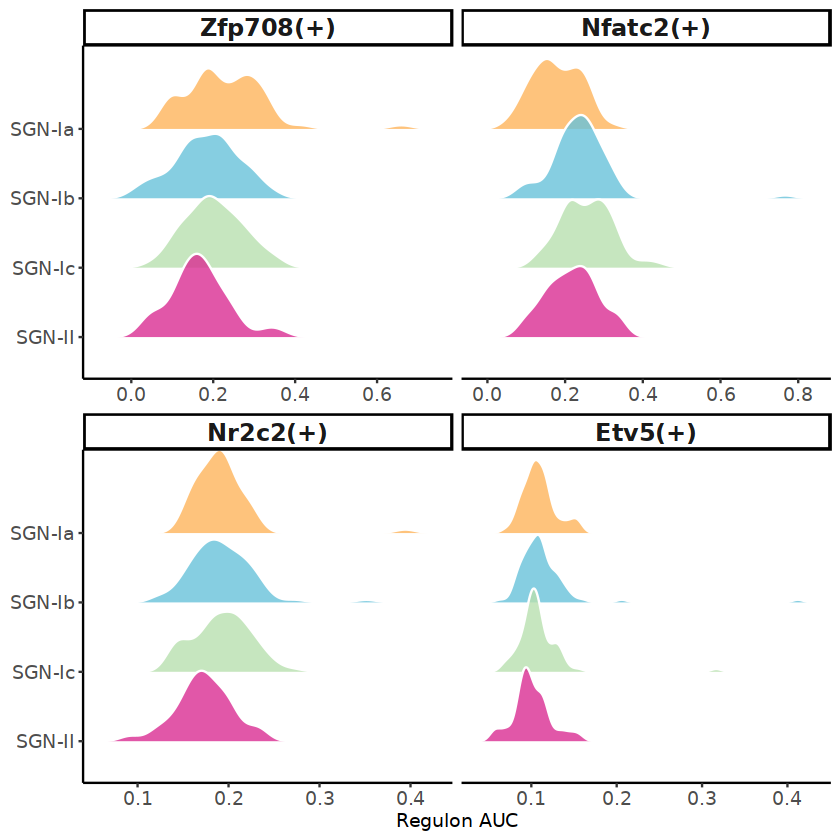

In [ ]:
library(ggplot2)
library(ggridges)
library(dplyr)
library(tidyr)
#regulonsToPlot <- c(  "Rxrg(+)","Creb1(+)","Gata3(+)","Cux1(+)","Grhl1(+)","Zbtb7c(+)")
regulonsToPlot <- c(  "Zfp708(+)","Nfatc2(+)","Nr2c2(+)","Etv5(+)")
# 按照已有细胞类型颜色设置顺序
group_order <- names(group_colors)

# 提取 AUC 数据
plot_df <- as.data.frame(auc[, regulonsToPlot, drop = FALSE])

plot_df$subtype <- meta$subtype_Final

# 转换为长格式
plot_df <- plot_df %>%
  pivot_longer(
    cols = all_of(regulonsToPlot),
    names_to = "Regulon",
    values_to = "AUC"
  ) %>%
  filter(subtype %in% group_order) %>%
  mutate(
    subtype = factor(subtype, levels = group_order),
    Regulon = factor(Regulon, levels = regulonsToPlot)
  )

# 绘制山脊图
p2 <- ggplot(
  plot_df,
  aes(x = AUC, y = subtype, fill = subtype)
) +
  geom_density_ridges(
    alpha = 0.8,
    scale = 1.2,
    color = "white"
  ) +
  facet_wrap(~Regulon, ncol = 2, scales = "free_x") +
  scale_fill_manual(values = group_colors) +
  scale_y_discrete(limits = rev(group_order)) +
  theme_classic() +
  theme(
    legend.position = "none",
    strip.text = element_text(size = 14, face = "bold"),
    axis.text.y = element_text(size = 11),
    axis.text.x = element_text(size = 11)
  ) +
  labs(
    x = "Regulon AUC",
    y = NULL
  )

p2
ggsave(
  filename = file.path(out_dir, "SGN-SCENIC_Regulon_RidgePlot.pdf"),
  plot = p2,
  width = 7,
  height = 7,
  dpi = 300,
  bg = "white"
)

In [ ]:
obj <- readRDS('/data/work/毕业文章/Figure2/Cochlea-SGN亚型/Cochlea-SGN注释/SGN&Glia/Glia-提纯/Glia-亚群细分/Merge-Glia-Final.rds')

In [ ]:
obj$subtype_Final <- obj$Glia_subtype

In [ ]:
auc_file <- "Glia_auc_matrix.csv"
out_dir <- file.path(dirname(auc_file), "Glia_SCENIC_plots")
dir.create(out_dir, recursive = TRUE, showWarnings = FALSE)

auc <- read.csv(
  auc_file,
  row.names = 1,
  check.names = FALSE
)
auc <- as.matrix(auc)

In [ ]:
meta <- obj@meta.data

stopifnot(
  all(c("Glia_subtype", "sample") %in% colnames(meta)),
  !anyDuplicated(rownames(auc)),
  !anyDuplicated(rownames(meta)),
  is.numeric(auc),
  all(is.finite(auc))
)

missing_cells <- setdiff(rownames(auc), rownames(meta))

if (length(missing_cells) > 0) {
  stop("部分 AUC 细胞在 obj 中找不到，请检查是否使用了同一个对象。")
}

In [ ]:
# 按 AUC 的细胞顺序排列注释，不能只按原来的行顺序拼接
meta <- meta[rownames(auc), c("Glia_subtype", "sample"), drop = FALSE]

stopifnot(
  identical(rownames(auc), rownames(meta)),
  !anyNA(meta)
)

# 固定亚群展示顺序
group_order <- c(
  "nmSC2",
  "nmSC1",
  "SGC",
  "mSC1",
  "Oligodendrocytes"
)

stopifnot(setequal(unique(as.character(meta$Glia_subtype)), group_order))

meta$Glia_subtype <- factor(meta$Glia_subtype, levels = group_order)
meta$sample <- factor(meta$sample)

# 检查结果：应为 1913 个细胞、42 个 regulon
dim(auc)
table(meta$Glia_subtype)
table(meta$Glia_subtype, meta$sample)

[1] 1913   42


           nmSC2            nmSC1              SGC             mSC1 
             741              521              344              268 
Oligodendrocytes 
              39 

                  
                   Y01818K9 Y40237E4
  nmSC2                 544      197
  nmSC1                 230      291
  SGC                   101      243
  mSC1                   45      223
  Oligodendrocytes       36        3

In [ ]:
group_colors <- c(
  "mSC1"         = "#FFE66D",
  "nmSC1"       = "#FDB45B",
  "nmSC2"      = "#68C1D9",
  "Oligodendrocytes" = "#B8DFAF",
  "SGC"            = "#D92E92"
)

relative_colors <- colorRampPalette(
  c("#2166AC", "#F7F7F7", "#B2182B")
)(100)

# 对每个 regulon 单独计算 Z-score
row_zscore <- function(x) {
  row_sd <- apply(x, 1, sd)
  row_sd[!is.finite(row_sd) | row_sd == 0] <- 1

  sweep(
    sweep(x, 1, rowMeans(x), "-"),
    1, row_sd, "/"
  )
}

In [ ]:
group_order <- names(group_colors)

mean_auc <- sapply(group_order, function(g) {
  colMeans(auc[meta$Glia_subtype == g, , drop = FALSE])
})

In [ ]:
# 手动设置 regulon 顺序
regulon_order <- c(
     "Nr2f2(+)", "Zfp558(+)", "Polr3a(+)",
    "Sox17(+)",
    "Bach2(+)", "Kdm5a(+)",  "Sox6(+)", 
    "Sox8(+)", "Srf(+)", "Zfp108(+)", "Klf15(+)", "Mzf1(+)",
    "Prdm16(+)","Mybl1(+)"
)

mean_auc <- mean_auc[regulon_order, , drop = FALSE]

In [ ]:
group_order <- names(group_colors)

mean_auc <- mean_auc[, group_order, drop = FALSE]
mean_auc_z <- row_zscore(mean_auc)

group_annotation <- data.frame(
  Glia_subtype = factor(group_order, levels = group_order),
  row.names = group_order
)

# 不显示细胞数，仅显示亚群名称
column_labels <- group_order

# 原始平均 AUC
pheatmap(
  mean_auc,
  color = colorRampPalette(c("#FFF7EC", "#FC8D59", "#7F0000"))(100),
  cluster_rows = FALSE,
  cluster_cols = FALSE,
  labels_col = column_labels,
  annotation_col = group_annotation,
  annotation_colors = list(Glia_subtype = group_colors),
  annotation_names_col = FALSE,
  border_color = NA,
  fontsize_row = 8,
  angle_col = 45,
  main = "Mean regulon activity by Glia subtype",
  filename = file.path(out_dir, "01_Glia_subtype_mean_AUC.pdf"),
  width = 10,
  height = 12
)

# 相对活性
z_limit <- max(abs(mean_auc_z))
if (z_limit == 0) z_limit <- 1




pheatmap(
  mean_auc_z,
  color = relative_colors,
  breaks = seq(-1, 1, length.out = 101),
  cluster_rows = FALSE,
  cluster_cols = FALSE,
  labels_col = column_labels,
  annotation_col = group_annotation,
  annotation_colors = list(Glia_subtype = group_colors),
  annotation_names_col = FALSE,
  border_color = NA,
  fontsize_row = 8,
  angle_col = 45,
  main = "Relative activity by Glia subtype (row Z-score)",
  filename = file.path(out_dir, "02_Glia_subtype_relative_筛选.pdf"),
  width = 6,
  height = 6
)

Picking joint bandwidth of 0.0111

Picking joint bandwidth of 0.0245

Picking joint bandwidth of 0.00745

Picking joint bandwidth of 0.014

Picking joint bandwidth of 0.00803

Picking joint bandwidth of 0.00627

Picking joint bandwidth of 0.0111

Picking joint bandwidth of 0.0245

Picking joint bandwidth of 0.00745

Picking joint bandwidth of 0.014

Picking joint bandwidth of 0.00803

Picking joint bandwidth of 0.00627



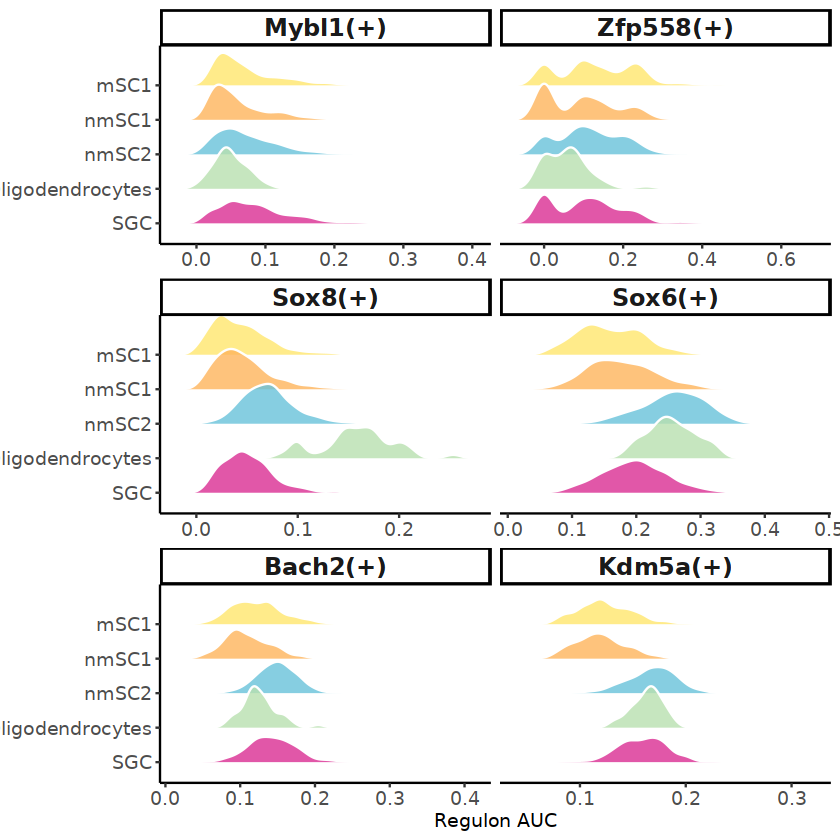

In [ ]:
library(ggplot2)
library(ggridges)
library(dplyr)
library(tidyr)
regulonsToPlot <- c(  "Mybl1(+)","Zfp558(+)","Sox8(+)","Sox6(+)","Bach2(+)","Kdm5a(+)")

# 按照已有细胞类型颜色设置顺序
group_order <- names(group_colors)

# 提取 AUC 数据
plot_df <- as.data.frame(auc[, regulonsToPlot, drop = FALSE])

plot_df$subtype <- meta$Glia_subtype

# 转换为长格式
plot_df <- plot_df %>%
  pivot_longer(
    cols = all_of(regulonsToPlot),
    names_to = "Regulon",
    values_to = "AUC"
  ) %>%
  filter(subtype %in% group_order) %>%
  mutate(
    subtype = factor(subtype, levels = group_order),
    Regulon = factor(Regulon, levels = regulonsToPlot)
  )

# 绘制山脊图
p2 <- ggplot(
  plot_df,
  aes(x = AUC, y = subtype, fill = subtype)
) +
  geom_density_ridges(
    alpha = 0.8,
    scale = 1.2,
    color = "white"
  ) +
  facet_wrap(~Regulon, ncol = 2, scales = "free_x") +
  scale_fill_manual(values = group_colors) +
  scale_y_discrete(limits = rev(group_order)) +
  theme_classic() +
  theme(
    legend.position = "none",
    strip.text = element_text(size = 14, face = "bold"),
    axis.text.y = element_text(size = 11),
    axis.text.x = element_text(size = 11)
  ) +
  labs(
    x = "Regulon AUC",
    y = NULL
  )

p2
ggsave(
  filename = file.path(out_dir, "Glia-SCENIC_Regulon_RidgePlot.pdf"),
  plot = p2,
  width = 7,
  height = 7,
  dpi = 300,
  bg = "white"
)

In [ ]:
obj <- readRDS('/data/work/毕业文章/Figure4/Merge-Epi-Final-V2.rds')

In [ ]:
auc_file <- "Epi_auc_matrix.csv"
out_dir <- file.path(dirname(auc_file), "Epi_SCENIC_plots")
dir.create(out_dir, recursive = TRUE, showWarnings = FALSE)

auc <- read.csv(
  auc_file,
  row.names = 1,
  check.names = FALSE
)
auc <- as.matrix(auc)

In [ ]:
meta <- obj@meta.data

stopifnot(
  all(c("subtype_Final", "sample") %in% colnames(meta)),
  !anyDuplicated(rownames(auc)),
  !anyDuplicated(rownames(meta)),
  is.numeric(auc),
  all(is.finite(auc))
)

missing_cells <- setdiff(rownames(auc), rownames(meta))

if (length(missing_cells) > 0) {
  stop("部分 AUC 细胞在 obj 中找不到，请检查是否使用了同一个对象。")
}

In [ ]:
# 按 AUC 的细胞顺序排列注释，不能只按原来的行顺序拼接
meta <- meta[rownames(auc), c("subtype_Final", "sample"), drop = FALSE]

stopifnot(
  identical(rownames(auc), rownames(meta)),
  !anyNA(meta)
)

# 固定亚群展示顺序
group_order <- c(
  "SV-MC",
  "ISC_OSC",
  "SV-Basal",
  "Spindle cells",
  "RM",
  "IPhC_IBC",
  "Hair Cells",
  "TBC"
)

stopifnot(setequal(unique(as.character(meta$subtype_Final)), group_order))

meta$subtype_Final <- factor(meta$subtype_Final, levels = group_order)
meta$sample <- factor(meta$sample)

# 检查结果：应为 1913 个细胞、42 个 regulon
dim(auc)
table(meta$subtype_Final)
table(meta$subtype_Final, meta$sample)

[1] 3588   10


        SV-MC       ISC_OSC      SV-Basal Spindle cells            RM 
         1193           628           527           424           376 
     IPhC_IBC    Hair Cells           TBC 
          190           139           111 

               
                Y01818K9 Y40237E4
  SV-MC              554      639
  ISC_OSC            196      432
  SV-Basal            82      445
  Spindle cells      229      195
  RM                 117      259
  IPhC_IBC            46      144
  Hair Cells          60       79
  TBC                 64       47

In [ ]:
group_colors <- colorlist <- c(
  "SV-MC"         = "#FFE66D",
  "ISC_OSC"       = "#FDB45B",
  "SV-Basal"      = "#68C1D9",
  "Spindle cells" = "#B8DFAF",
  "RM"            = "#D92E92",
  "IPhC_IBC"      = "#9FC5E8",
  "Hair Cells"    = "#C7B5E3",
  "TBC"           = "#A9D18E"
)

relative_colors <- colorRampPalette(
  c("#2166AC", "#F7F7F7", "#B2182B")
)(100)

# 对每个 regulon 单独计算 Z-score
row_zscore <- function(x) {
  row_sd <- apply(x, 1, sd)
  row_sd[!is.finite(row_sd) | row_sd == 0] <- 1

  sweep(
    sweep(x, 1, rowMeans(x), "-"),
    1, row_sd, "/"
  )
}

In [ ]:
group_order <- names(group_colors)

mean_auc <- sapply(group_order, function(g) {
  colMeans(auc[meta$subtype_Final == g, , drop = FALSE])
})

In [ ]:
# 手动设置 regulon 顺序
regulon_order <- c(
  "Hmx2(+)",
  "Arnt2(+)",
  "Gtf2i(+)",
  "Pbx3(+)",
  "Pou3f1(+)",
  "Irf8(+)",
  "Rorb(+)",
  "Zmat4(+)",
  "6720489N17Rik(+)",
  "Brf1(+)"
)

mean_auc <- mean_auc[regulon_order, , drop = FALSE]

In [ ]:
group_order <- names(group_colors)

mean_auc <- mean_auc[, group_order, drop = FALSE]
mean_auc_z <- row_zscore(mean_auc)

group_annotation <- data.frame(
  Glia_subtype = factor(group_order, levels = group_order),
  row.names = group_order
)

# 不显示细胞数，仅显示亚群名称
column_labels <- group_order

# 原始平均 AUC
pheatmap(
  mean_auc,
  color = colorRampPalette(c("#FFF7EC", "#FC8D59", "#7F0000"))(100),
  cluster_rows = FALSE,
  cluster_cols = FALSE,
  labels_col = column_labels,
  annotation_col = group_annotation,
  annotation_colors = list(Glia_subtype = group_colors),
  annotation_names_col = FALSE,
  border_color = NA,
  fontsize_row = 8,
  angle_col = 45,
  main = "Mean regulon activity by Glia subtype",
  filename = file.path(out_dir, "01_Epi_subtype_mean_AUC.pdf"),
  width = 10,
  height = 12
)

# 相对活性
z_limit <- max(abs(mean_auc_z))
if (z_limit == 0) z_limit <- 1




pheatmap(
  mean_auc_z,
  color = relative_colors,
  breaks = seq(-1, 1, length.out = 101),
  cluster_rows = FALSE,
  cluster_cols = FALSE,
  labels_col = column_labels,
  annotation_col = group_annotation,
  annotation_colors = list(Glia_subtype = group_colors),
  annotation_names_col = FALSE,
  border_color = NA,
  fontsize_row = 8,
  angle_col = 45,
  main = "Relative activity by Glia subtype (row Z-score)",
  filename = file.path(out_dir, "02_Epi_subtype_relative_筛选.pdf"),
  width = 6,
  height = 6
)

Picking joint bandwidth of 0.0114

Picking joint bandwidth of 0.0192

Picking joint bandwidth of 0.0359

Picking joint bandwidth of 0.0383

Picking joint bandwidth of 0.0104

Picking joint bandwidth of 0.0114

Picking joint bandwidth of 0.0192

Picking joint bandwidth of 0.0359

Picking joint bandwidth of 0.0383

Picking joint bandwidth of 0.0104



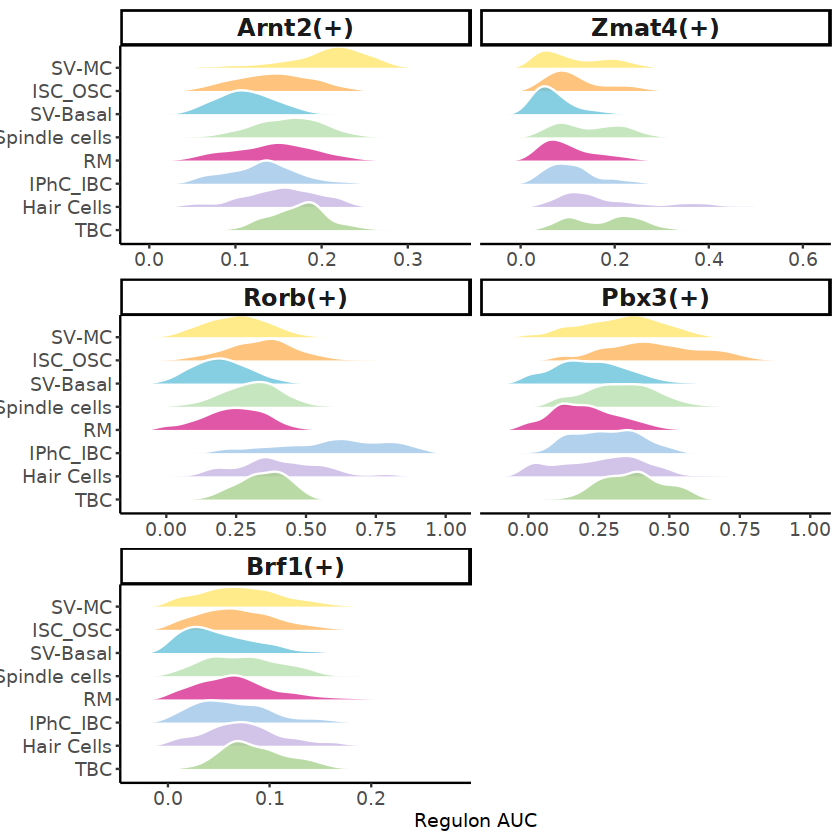

In [ ]:
library(ggplot2)
library(ggridges)
library(dplyr)
library(tidyr)
regulonsToPlot <- c(  "Arnt2(+)","Zmat4(+)","Rorb(+)","Pbx3(+)","Brf1(+)")

# 按照已有细胞类型颜色设置顺序
group_order <- names(group_colors)

# 提取 AUC 数据
plot_df <- as.data.frame(auc[, regulonsToPlot, drop = FALSE])

plot_df$subtype <- meta$subtype_Final

# 转换为长格式
plot_df <- plot_df %>%
  pivot_longer(
    cols = all_of(regulonsToPlot),
    names_to = "Regulon",
    values_to = "AUC"
  ) %>%
  filter(subtype %in% group_order) %>%
  mutate(
    subtype = factor(subtype, levels = group_order),
    Regulon = factor(Regulon, levels = regulonsToPlot)
  )

# 绘制山脊图
p2 <- ggplot(
  plot_df,
  aes(x = AUC, y = subtype, fill = subtype)
) +
  geom_density_ridges(
    alpha = 0.8,
    scale = 1.2,
    color = "white"
  ) +
  facet_wrap(~Regulon, ncol = 2, scales = "free_x") +
  scale_fill_manual(values = group_colors) +
  scale_y_discrete(limits = rev(group_order)) +
  theme_classic() +
  theme(
    legend.position = "none",
    strip.text = element_text(size = 14, face = "bold"),
    axis.text.y = element_text(size = 11),
    axis.text.x = element_text(size = 11)
  ) +
  labs(
    x = "Regulon AUC",
    y = NULL
  )

p2
ggsave(
  filename = file.path(out_dir, "Epi-SCENIC_Regulon_RidgePlot.pdf"),
  plot = p2,
  width = 7,
  height = 7,
  dpi = 300,
  bg = "white"
)